In [40]:
import pandas as pd
import numpy as np
from sklearn import preprocessing
import matplotlib.pyplot as plt
plt.rc("font" ,size = 14)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split #Train Test Split
import seaborn as sns #visualization
sns.set(style="whitegrid", color_codes=True) #visualization


In [41]:
import os

os.getcwd()

'C:\\Users\\aaa'

In [42]:
df = pd.read_excel(
    "C:\\Users\\aaa\\OneDrive\\Desktop\\Datasets\\Bank\\default+of+credit+card+clients\default of credit card clients.xlsx",skiprows=1
)

df

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,Unnamed: 25,Unnamed: 26,Unnamed: 27,default payment,Unnamed: 29,Unnamed: 30,x1=limit,dollar,Unnamed: 33,Unnamed: 34
0,1,20000,2,2,1,24,2,2,-1,-1,...,NaN,NaN,NaN,0=no,NaN,NaN,x2=gender,"1=male,2=fe",NaN,NaN
1,2,120000,2,2,2,26,-1,2,0,0,...,NaN,NaN,NaN,1-yes,NaN,NaN,x3=schooling,NaN,NaN,NaN
2,3,90000,2,2,2,34,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x4=maritial status,1=married,2=single,3=other
3,4,50000,2,2,1,37,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x5=age,NaN,NaN,NaN
4,5,50000,1,2,1,57,-1,0,-1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x6-x11=histroy of past pay,"x6=sep,x11=april","-1=on time,8=late by 8months",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29997,29998,30000,1,2,2,37,4,3,2,-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29998,29999,80000,1,3,1,41,1,-1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
df1=df.iloc[:25].copy()
df1

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,Unnamed: 25,Unnamed: 26,Unnamed: 27,default payment,Unnamed: 29,Unnamed: 30,x1=limit,dollar,Unnamed: 33,Unnamed: 34
0,1,20000,2,2,1,24,2,2,-1,-1,...,NaN,NaN,NaN,0=no,NaN,NaN,x2=gender,"1=male,2=fe",NaN,NaN
1,2,120000,2,2,2,26,-1,2,0,0,...,NaN,NaN,NaN,1-yes,NaN,NaN,x3=schooling,NaN,NaN,NaN
2,3,90000,2,2,2,34,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x4=maritial status,1=married,2=single,3=other
3,4,50000,2,2,1,37,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x5=age,NaN,NaN,NaN
4,5,50000,1,2,1,57,-1,0,-1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x6-x11=histroy of past pay,"x6=sep,x11=april","-1=on time,8=late by 8months",NaN
5,6,50000,1,1,2,37,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x12-x17=amtof bill,dollar,NaN,NaN
6,7,500000,1,1,2,29,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,x18-x23=bill paid amt,dollar,NaN,NaN
7,8,100000,2,2,2,23,0,-1,-1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,140000,2,3,1,28,0,0,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,10,20000,1,3,2,35,-2,-2,-2,-2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
del df1

In [45]:
df1 = df.iloc[:, :25].copy()
df1

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [46]:
y=df1["default payment next month"]

del y

C:\Users\aaa\AppData\Local\Temp\ipykernel_3708\2002449139.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="default payment next month",data=df1,palette="hls")


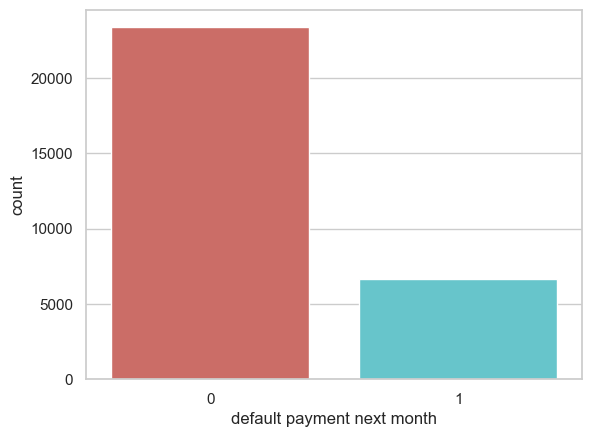

default payment next month
0    23364
1     6636
Name: count, dtype: int64


In [47]:
sns.countplot(x="default payment next month",data=df1,palette="hls")
plt.show()
print(df1["default payment next month"].value_counts())

In [48]:
df1.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [49]:
stat_df1=pd.DataFrame(df1.describe(include="all"))
stat_df1

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [50]:
df1.duplicated().sum()

np.int64(0)

In [51]:
X=df1.drop("default payment next month",axis=1)
y=df1["default payment next month"]

In [52]:
X = X.drop("ID", axis=1)

SEX
2    18112
1    11888
Name: count, dtype: int64


<Axes: xlabel='SEX', ylabel='count'>

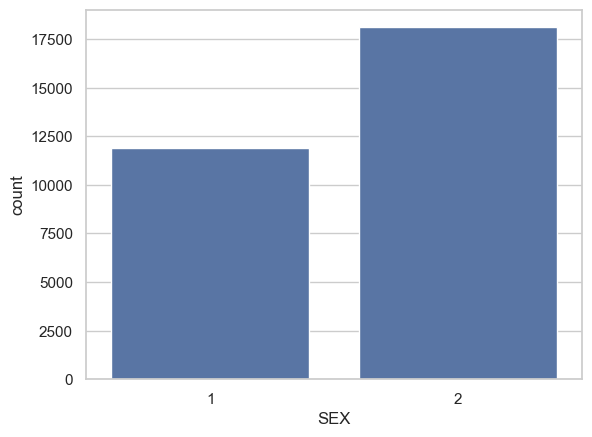

In [53]:
print (df1["SEX"].value_counts())
sns.countplot(x="SEX",data=df1)
# 1.male
# 2.female



EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64


<Axes: xlabel='EDUCATION', ylabel='count'>

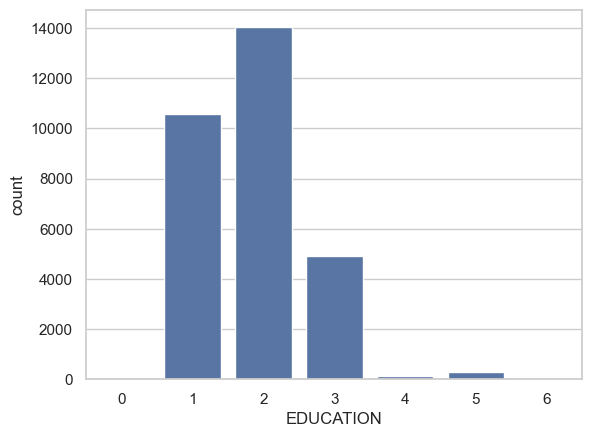

In [54]:
print(df1["EDUCATION"].value_counts())
sns.countplot(x="EDUCATION",data=df1)
#1 = graduate school; 2 = university; 3 = high school; 4 = others


MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64


<Axes: xlabel='MARRIAGE', ylabel='count'>

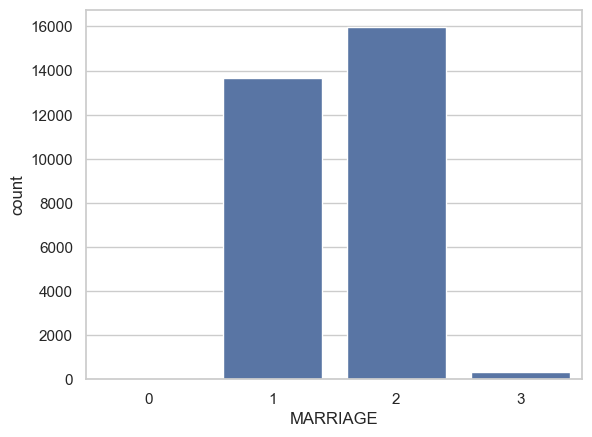

In [55]:
print(df1["MARRIAGE"].value_counts())
sns.countplot(x="MARRIAGE",data=df1)
#1 = married; 2 = single; 3 = others

In [56]:
lower_limit= df1["AGE"].min()
upper_limit= df1["AGE"].max()
print(lower_limit)
print(upper_limit)



21
79


In [57]:
bins=[0,10,20,30,40,50,60,70,80]
df1['age_grp']=pd.cut(df1['AGE'],bins=bins,right=True)
print (df1['age_grp'])

0        (20, 30]
1        (20, 30]
2        (30, 40]
3        (30, 40]
4        (50, 60]
           ...   
29995    (30, 40]
29996    (40, 50]
29997    (30, 40]
29998    (40, 50]
29999    (40, 50]
Name: age_grp, Length: 30000, dtype: category
Categories (8, interval[int64, right]): [(0, 10] < (10, 20] < (20, 30] < (30, 40] < (40, 50] < (50, 60] < (60, 70] < (70, 80]]


In [58]:
age_count = df1.groupby('age_grp', observed=True)['AGE'].count()

print(age_count)

age_grp
(20, 30]    11013
(30, 40]    10713
(40, 50]     6005
(50, 60]     1997
(60, 70]      257
(70, 80]       15
Name: AGE, dtype: int64


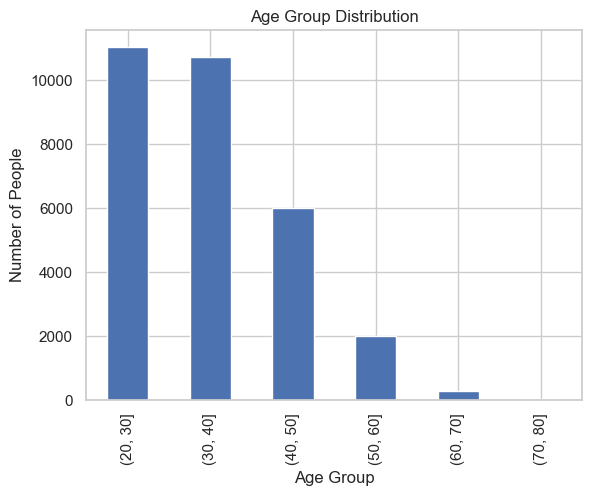

In [59]:
age_count.plot(kind='bar')

plt.xlabel('Age Group')
plt.ylabel('Number of People')
plt.title('Age Group Distribution')
plt.show()

In [60]:
X.shape
y.shape

(30000,)

In [61]:
df1.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month', 'age_grp'],
      dtype='object')

In [62]:
df1=df1.drop(["ID","age_grp"],axis=1)


In [63]:
df1.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='object')

In [64]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3",
            "PAY_4", "PAY_5", "PAY_6"]

for col in pay_cols:
    print(f"\n{col}")
    print(sorted(df1[col].dropna().unique()))


PAY_0
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_2
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_3
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_4
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_5
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_6
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [65]:
categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [66]:
print(X.columns)

Index(['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
       'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
       'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'SEX_2', 'EDUCATION_1',
       'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'EDUCATION_5',
       'EDUCATION_6', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3', 'PAY_0_-1',
       'PAY_0_0', 'PAY_0_1', 'PAY_0_2', 'PAY_0_3', 'PAY_0_4', 'PAY_0_5',
       'PAY_0_6', 'PAY_0_7', 'PAY_0_8', 'PAY_2_-1', 'PAY_2_0', 'PAY_2_1',
       'PAY_2_2', 'PAY_2_3', 'PAY_2_4', 'PAY_2_5', 'PAY_2_6', 'PAY_2_7',
       'PAY_2_8', 'PAY_3_-1', 'PAY_3_0', 'PAY_3_1', 'PAY_3_2', 'PAY_3_3',
       'PAY_3_4', 'PAY_3_5', 'PAY_3_6', 'PAY_3_7', 'PAY_3_8', 'PAY_4_-1',
       'PAY_4_0', 'PAY_4_1', 'PAY_4_2', 'PAY_4_3', 'PAY_4_4', 'PAY_4_5',
       'PAY_4_6', 'PAY_4_7', 'PAY_4_8', 'PAY_5_-1', 'PAY_5_0', 'PAY_5_2',
       'PAY_5_3', 'PAY_5_4', 'PAY_5_5', 'PAY_5_6', 'PAY_5_7', 'PAY_5_8',
       'PAY_6_-1', 'PAY_6_0', 'PAY_6_2', 'PAY_6_3', 'P

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [70]:
y_pred = log_model.predict(X_test_scaled)

In [71]:
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [72]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.8161666666666667

In [73]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000



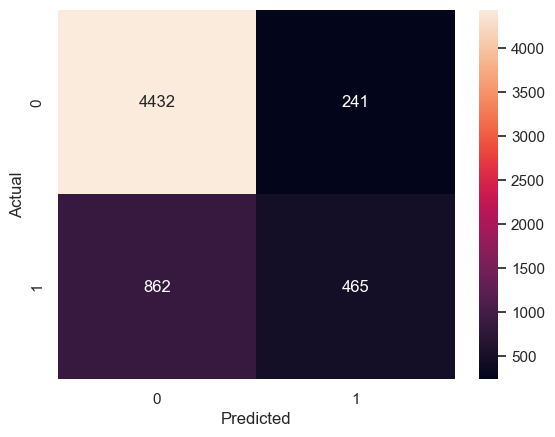

In [74]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [77]:
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [78]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0]
})

coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
27,PAY_0_2,0.584475
21,MARRIAGE_1,0.561225
22,MARRIAGE_2,0.497749
51,PAY_3_6,0.349539
26,PAY_0_1,0.282346
...,...,...
74,PAY_6_0,-0.169132
8,PAY_AMT1,-0.185676
33,PAY_0_8,-0.193697
80,PAY_6_7,-0.231292


In [79]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_prob)

np.float64(0.7564344933318777)

In [80]:
coefficients["Odds_Ratio"] = np.exp(coefficients["Coefficient"])
coefficients.sort_values(by="Odds_Ratio", ascending=False)

,Feature,Coefficient,Odds_Ratio
27,PAY_0_2,0.584475,1.794049
21,MARRIAGE_1,0.561225,1.752818
22,MARRIAGE_2,0.497749,1.645015
51,PAY_3_6,0.349539,1.418413
26,PAY_0_1,0.282346,1.326238
...,...,...,...
74,PAY_6_0,-0.169132,0.844397
8,PAY_AMT1,-0.185676,0.830542
33,PAY_0_8,-0.193697,0.823907
80,PAY_6_7,-0.231292,0.793508


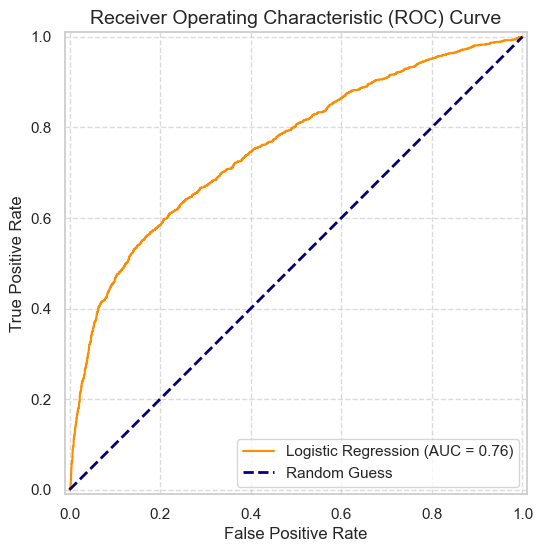

In [81]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Create the ROC curve plot using your true test labels and predicted probabilities
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(
    y_test, 
    y_prob, 
    name="Logistic Regression", 
    color="darkorange", 
    ax=ax
)

# Add diagonal reference line for random guessing
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess")

# Customize plot titles and labels
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=14)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.7)

# Show the plot
plt.show()

In [82]:
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>